In [1]:
import numpy as np
import matplotlib.pyplot as plt
from lmfit import models
from scipy.optimize import leastsq
from scipy.optimize import curve_fit
import os
import pandas as pd


In [66]:
def importeer(datanaam):
    x_as = []
    y_as = []

    # open file in read mode
    with open(datanaam, 'r', newline='') as file:

        # read and discard first line of file
        next(file)

        for line in file:
            # split column

            line_splitted = line.split(',')
            x = (float(line_splitted[3]))
            y = float(line_splitted[4])
            if x < 0.015:
                x_as.append(x)
                y_as.append(y)

    return x_as, y_as


def lorentz(x, x0, gamma, A):
    return A * ( gamma)**2 / ((x - x0)**2 + (gamma)**2)

def multi_lorentz(x, *params):
    B = params[-1]
    y = np.zeros_like(x, dtype=float) + B
    for i in range(0, len(params) - 1, 3):
        y += lorentz(x, params[i], params[i+1], params[i+2])
    return y


# ── Hoofd-fitfunctie ──────────────────────────────────────────────────────────

def lorentz_fit(x, y, x0_list, A_list,
                gamma_guess=0.001, B_guess=0.0,
                plot=True, title='Lorentz Fit'):
    
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)

    if len(x0_list) != len(A_list):
        raise ValueError("x0_list en A_list moeten even lang zijn.")

    # Startwaarden opbouwen
    p0 = []
    for x0, A in zip(x0_list, A_list):
        p0.extend([x0, gamma_guess, A])
    p0.append(B_guess)

    # Fit
    popt, pcov = curve_fit(multi_lorentz, x, y, p0=p0, maxfev=100000)
    perr = np.sqrt(np.diag(pcov))
    y_fit = multi_lorentz(x, *popt)

    # Resultaten printen
    N = len(x0_list)
    print(f"{'─'*45}")
    for i in range(N):
        print(f"Piek {i+1}:")
        print(f"  x0    = {popt[i*3]:.5f} ± {perr[i*3]:.5f}")
        print(f"  gamma = {popt[i*3+1]:.5f} ± {perr[i*3+1]:.5f}")
        print(f"  A     = {popt[i*3+2]:.5f} ± {perr[i*3+2]:.5f}")
    print(f"Achtergrond B = {popt[-1]:.5f} ± {perr[-1]:.5f}")
    print(f"{'─'*45}")

    # Plot
    if plot:
        fig, ax = plt.subplots(figsize=(10, 4))
        ax.plot(x, y,     color='green',  label='Data', lw=1.2)
        ax.plot(x, y_fit, color='orange', label='Lorentz fit', lw=1.8, ls='--')

        # Individuele pieken (stippellijnen)
        for i in range(N):
            x0_i, g_i, A_i = popt[i*3], popt[i*3+1], popt[i*3+2]
            B_i = popt[-1]
            y_i = lorentz(x, x0_i, g_i, A_i) + B_i
            ax.plot(x, y_i, lw=0.8, ls=':', label=f'Piek {i+1}')

        ax.set_xlabel('Time (s)')
        ax.set_ylabel('Voltage (V)')
        ax.set_title(title)
        ax.legend()
        plt.tight_layout()
        plt.show()

    return popt, perr

def subtract(x_foreground, y_foreground, x_background, y_background):
    y_interpolated = np.interp(x_foreground, x_background, y_background)
    y_subtracted = y_foreground - y_interpolated

    return x_foreground, y_subtracted


def load_file(number: int, folder_path) -> pd.DataFrame:

    filename = f"TEK{number:04d}.CSV"
    filepath = os.path.join(folder_path, filename)

    if not os.path.exists(filepath):
        print(f"Bestand niet gevonden: {filename}")
        return None

    df = pd.read_csv(
        filepath,
        header=None,
        usecols=[3, 4],
        names=["time", "voltage"],
        encoding="utf-8"
    )

    # Verwijder rijen waar time of voltage geen getal is (de metadata-rijen)
    df = df.apply(pd.to_numeric, errors="coerce").dropna().reset_index(drop=True)

    #print(f"Geladen: {filename} — {len(df)} datapunten")
    x_as = df["time"].values
    y_as = df["voltage"].values
    return x_as, y_as
def file_data(folder_path, N):
    x_subs = []
    y_subs = []

    block_size   = 10   # 10 paren per blok
    block_stride = 20   # sprong tussen blokken (10→30→50→...)
    fg_start     = 10   # eerste foreground index

    fg_block_start = fg_start

    while fg_block_start < N:
        for k in range(block_size):
            fg = fg_block_start + k        # foreground 10..19, 30..39, ...
            bg = fg - 10                   # background 0..9, 20..29, ...

            if fg >= N:
                break

            # Laad foreground & background
            result_fg = load_file(fg, folder_path)
            result_bg = load_file(bg, folder_path)

            if result_fg is None or result_bg is None:
                print(f"Overgeslagen: TEK{fg:04d} of TEK{bg:04d} niet gevonden.")
                continue

            x_foreground, y_foreground = result_fg
            x_background, y_background = result_bg

            # Subtract
            x_subtracted, y_subtracted = subtract(
                x_foreground, y_foreground,
                x_background, y_background
            )

            x_subs.append(x_subtracted)
            y_subs.append(y_subtracted)

            # Desgewenst plotten:
            plt.plot(x_subtracted, y_subtracted)
            plt.xlabel("Time (s)")
            plt.ylabel("Voltage (V)")
            plt.title(f"Voltage vs Time - TEK{fg:04d} - TEK{bg:04d}, subtracted")
            plt.show()

        # Volgend blok (10→30→50→...)
        fg_block_start += block_stride

    return x_subs, y_subs

def gemiddelde_grafiek(x_lijst, y_lijst):

    # Gemeenschappelijk x-bereik: van het hoogste minimum tot het laagste maximum
    # (zodat alle grafieken overlappen op dit bereik)
    x_min = max(np.min(x) for x in x_lijst)
    x_max = min(np.max(x) for x in x_lijst)

    # Aantal punten = gemiddelde lengte van de sub-lijsten
    n_punten = int(np.mean([len(x) for x in x_lijst]))

    x_communal = np.linspace(x_min, x_max, n_punten)

    # Interpoleer elke grafiek op het gemeenschappelijke x-grid
    y_geinterpoleerd = np.array([
        np.interp(x_communal, x, y)
        for x, y in zip(x_lijst, y_lijst)
    ])

    # Gemiddelde over alle grafieken
    y_gemiddeld = np.mean(y_geinterpoleerd, axis=0)

    return x_communal, y_gemiddeld

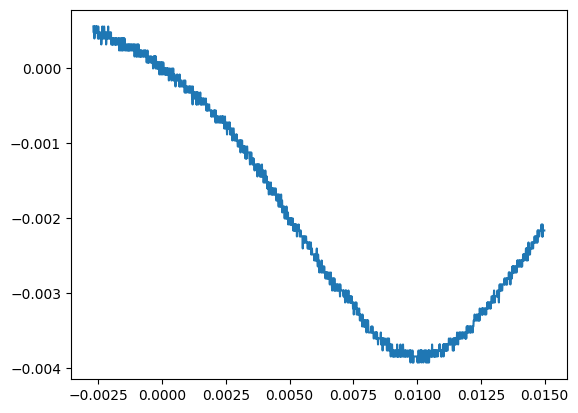

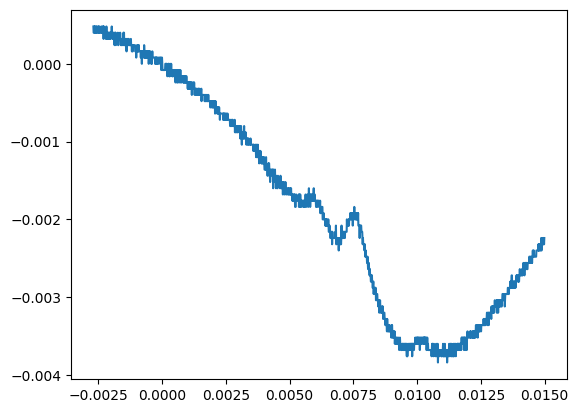

In [17]:
#1 importeren 
x_1,y_1 = importeer('/Users/timwiemer/Desktop/Natuur  en Sterrenkunde/Jaar 1/Rubium_Spectroscopy_group_11/Cross_over_dips_2026_06_11_16_avg/TEK0000.CSV')
x_2,y_2 = importeer('/Users/timwiemer/Desktop/Natuur  en Sterrenkunde/Jaar 1/Rubium_Spectroscopy_group_11/Cross_over_dips_2026_06_11_16_avg/TEK0010.CSV')


plt.plot(x_1,y_1)
plt.show()

plt.plot(x_2,y_2)
plt.show()

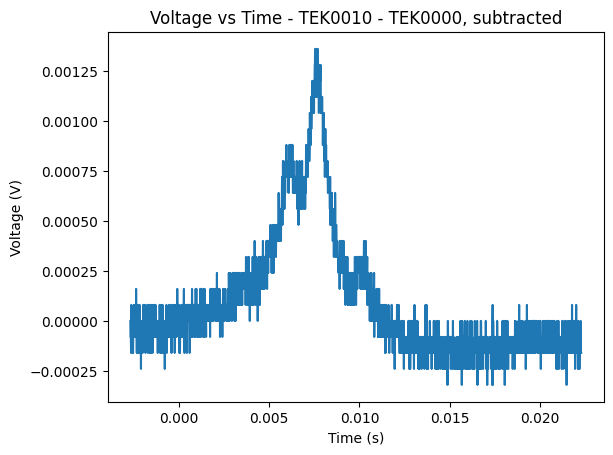

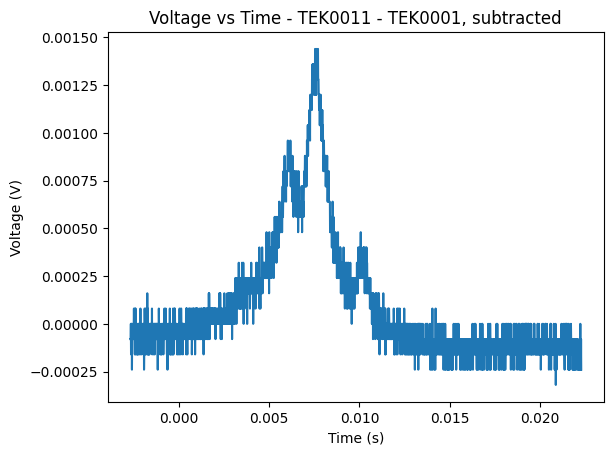

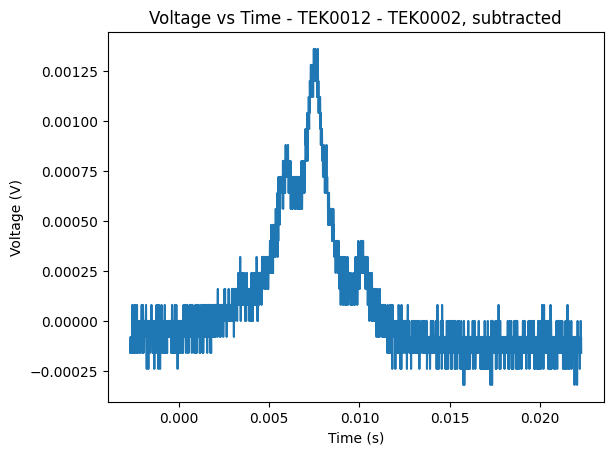

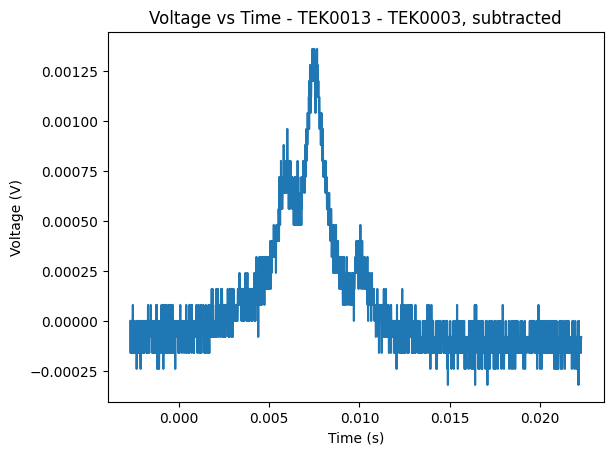

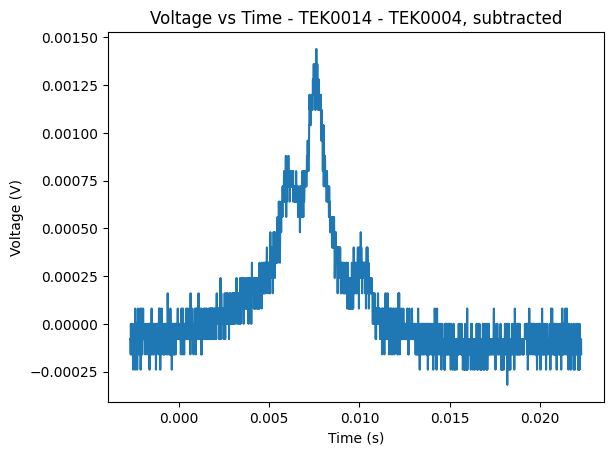

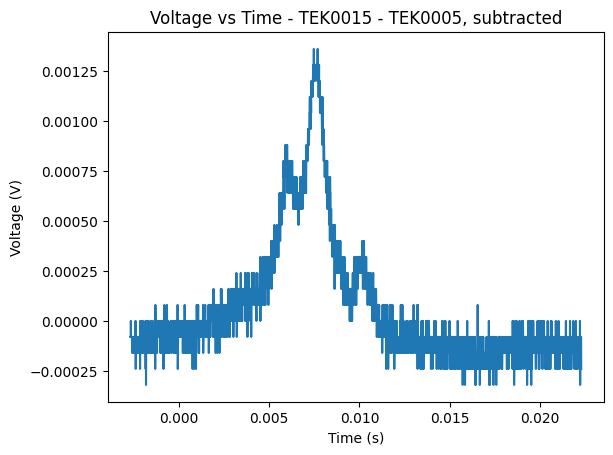

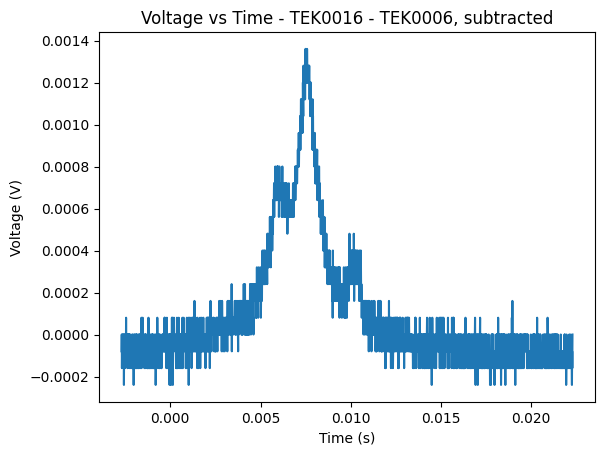

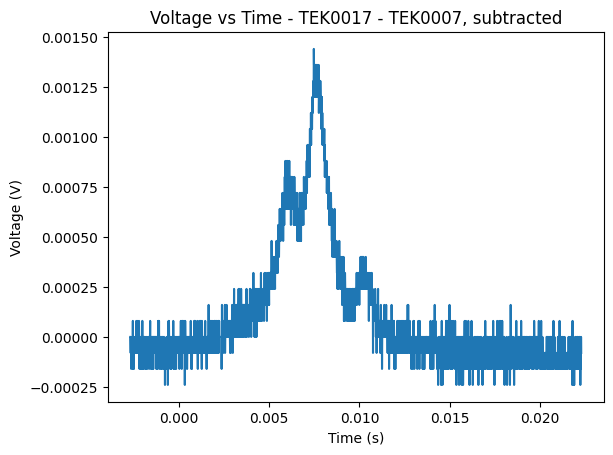

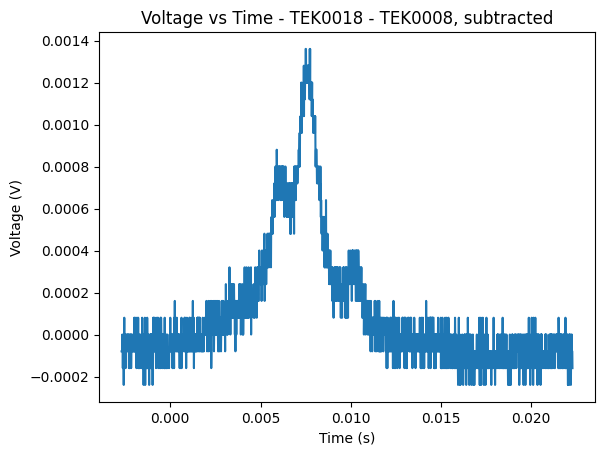

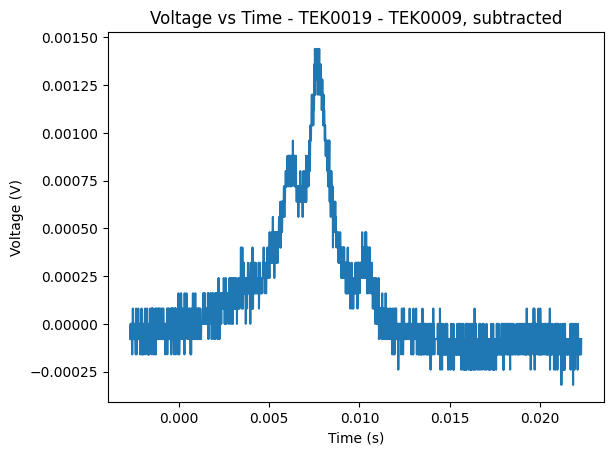

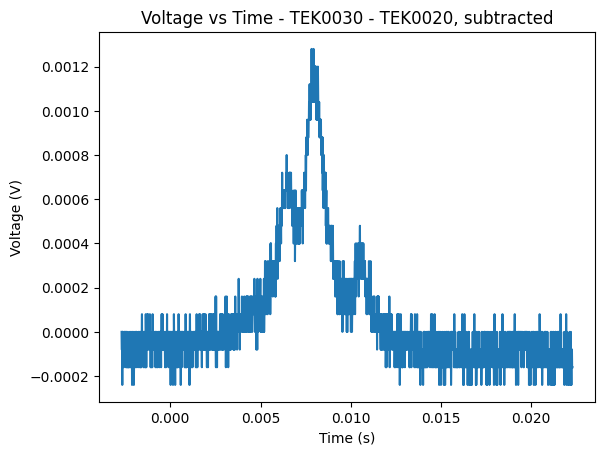

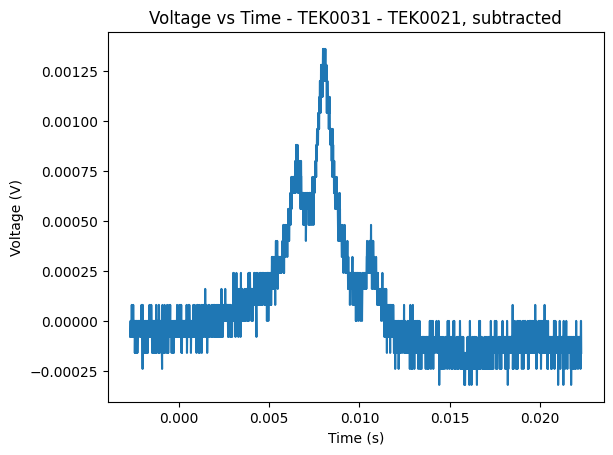

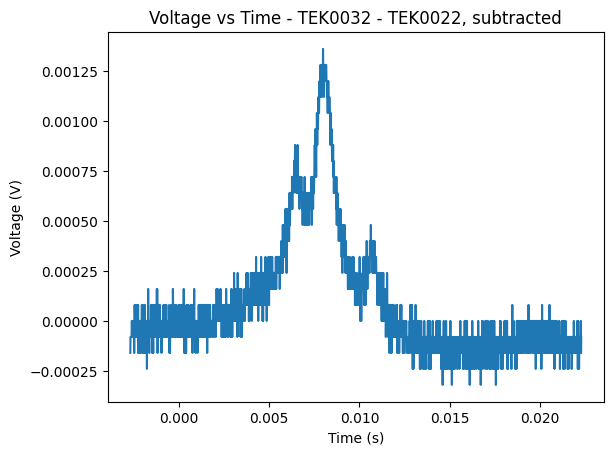

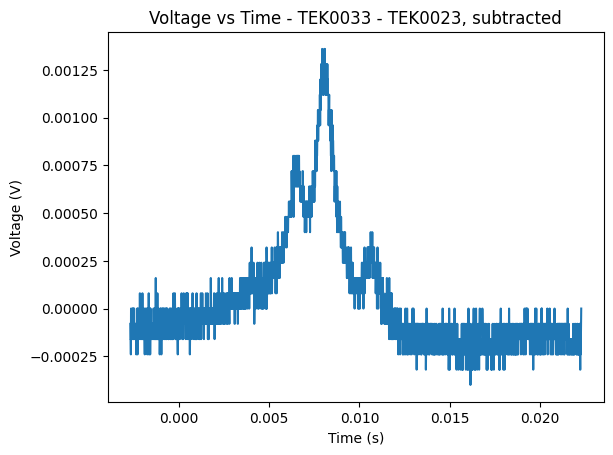

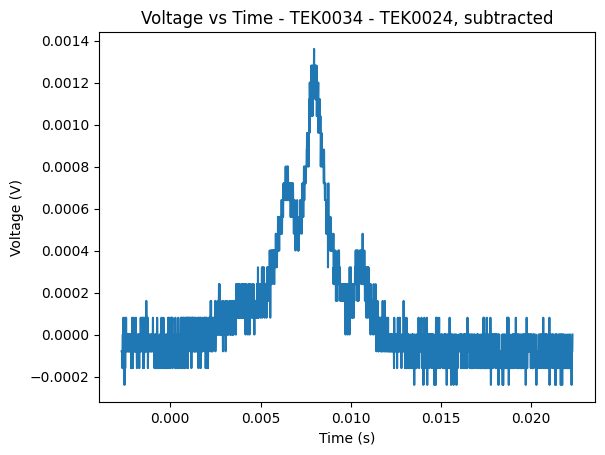

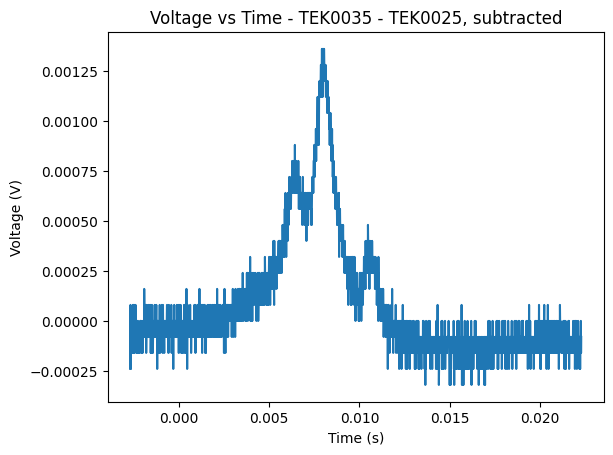

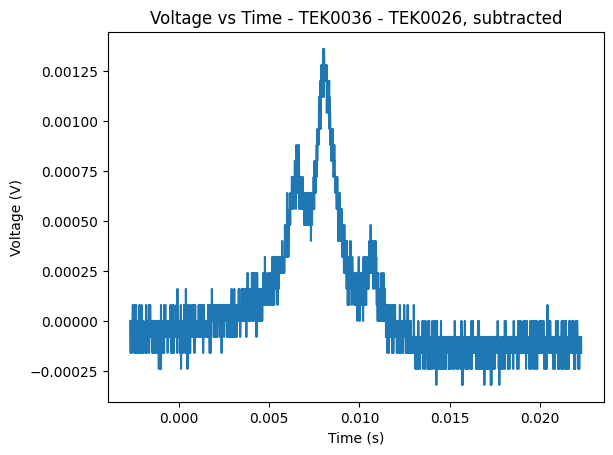

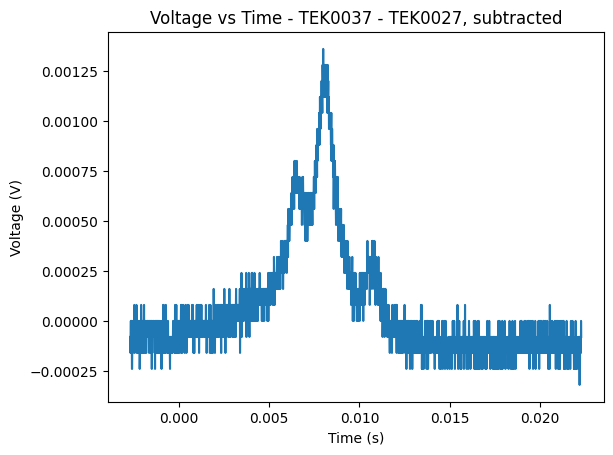

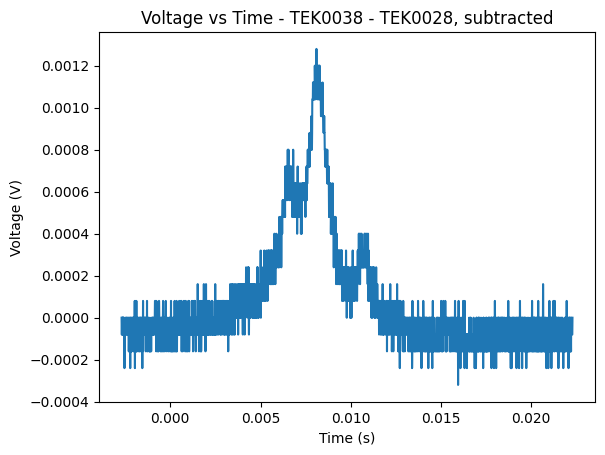

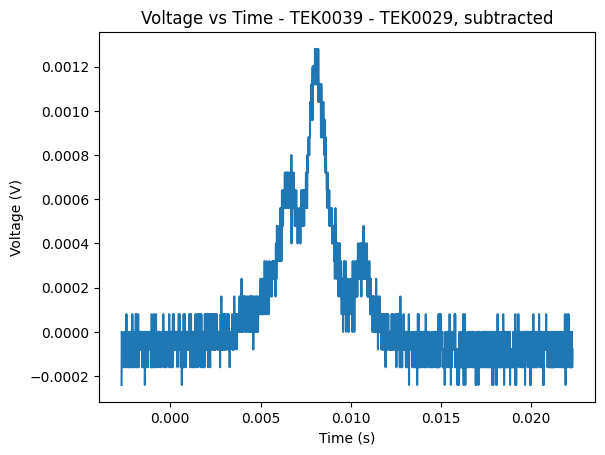

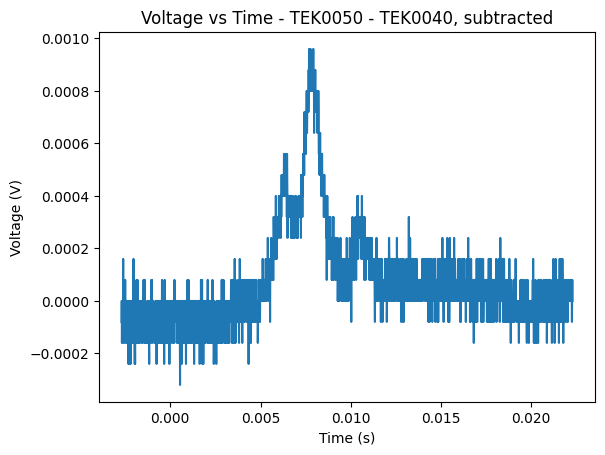

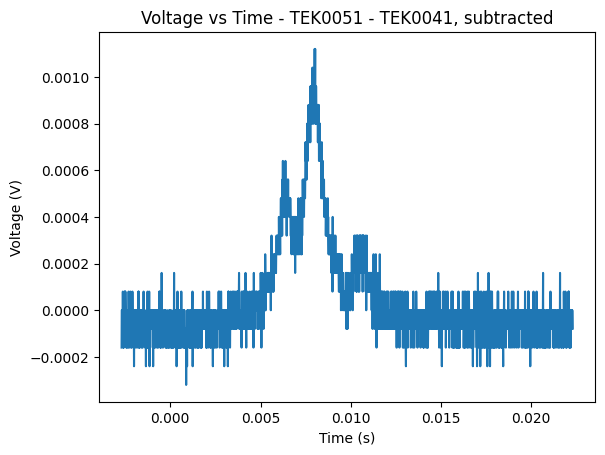

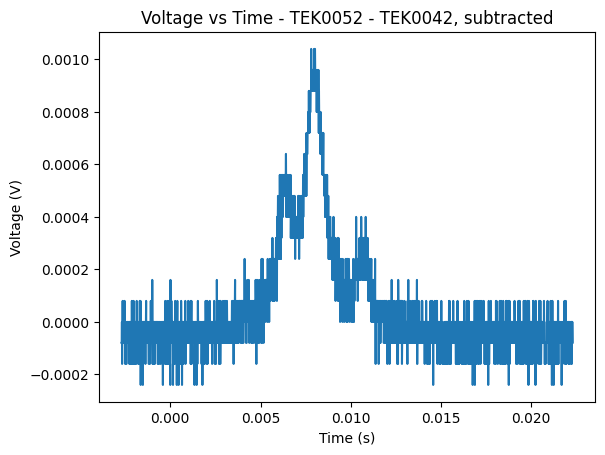

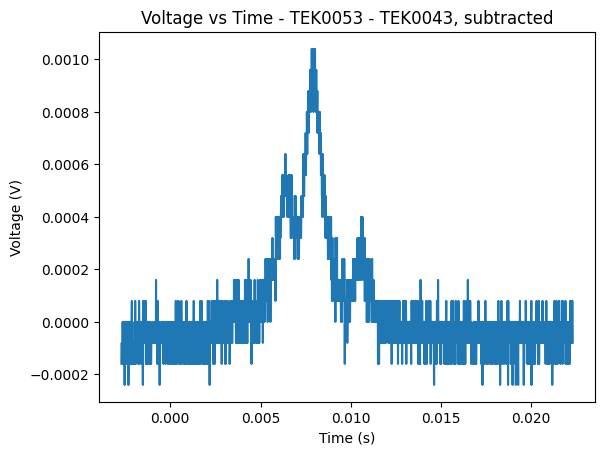

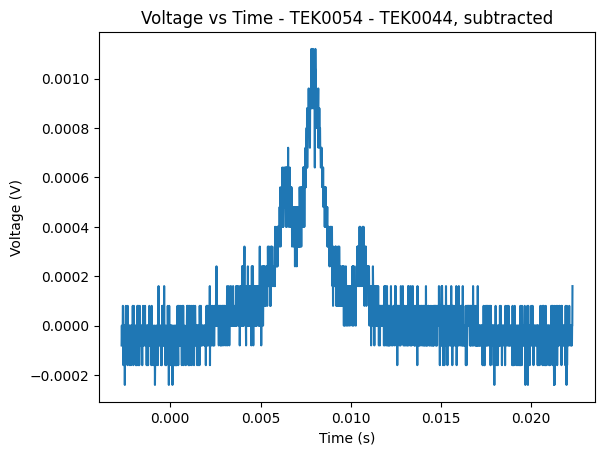

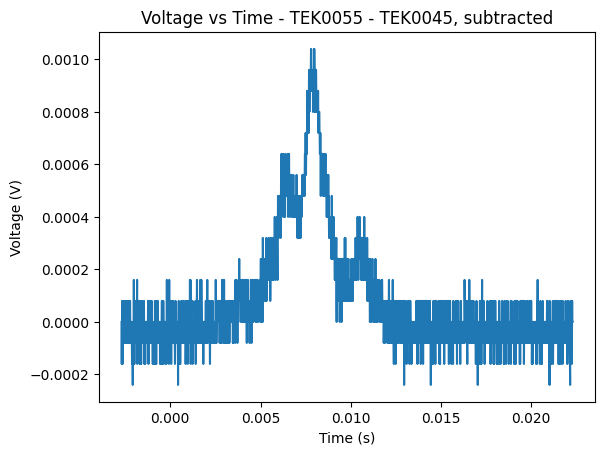

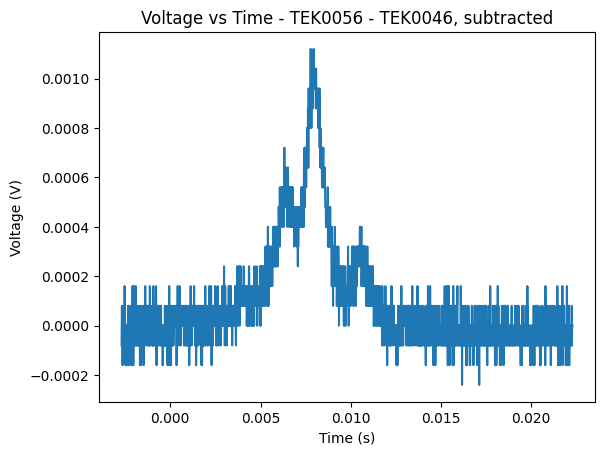

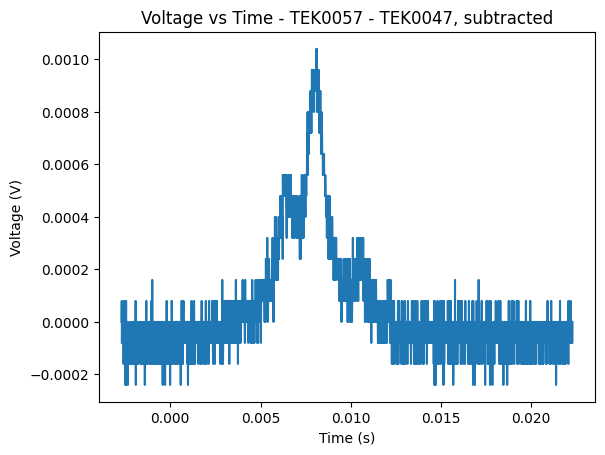

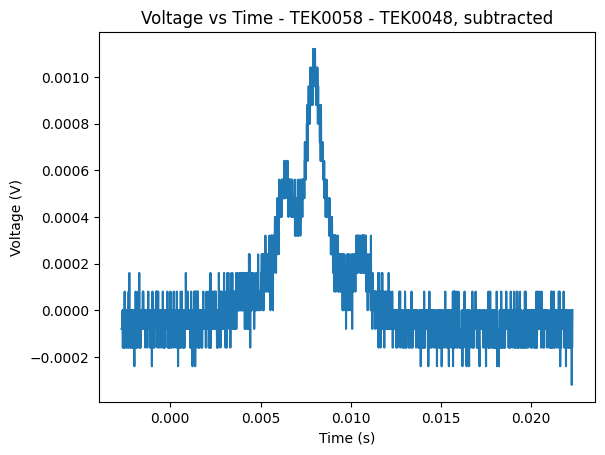

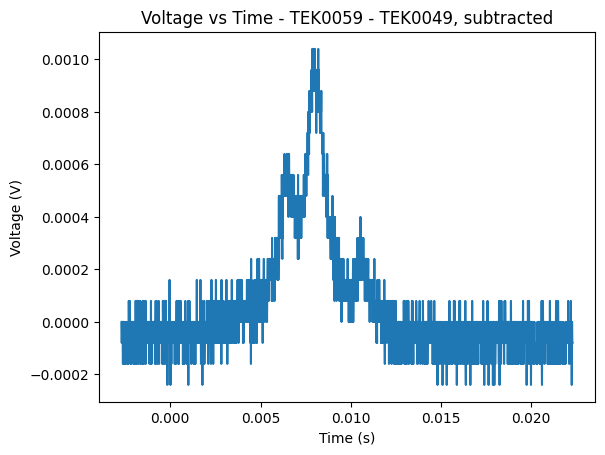

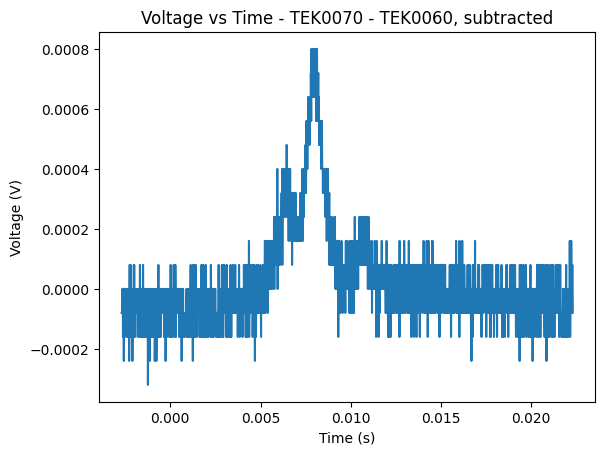

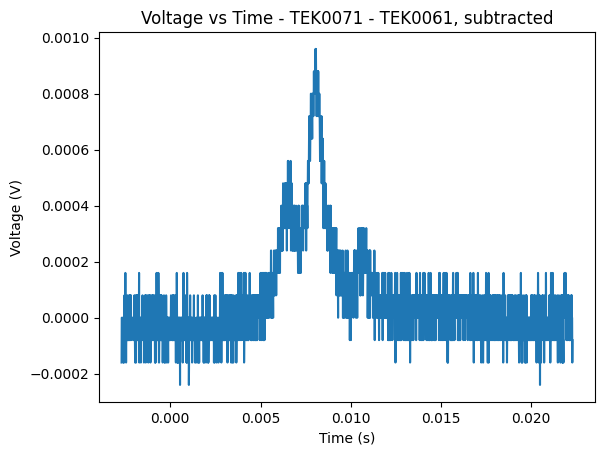

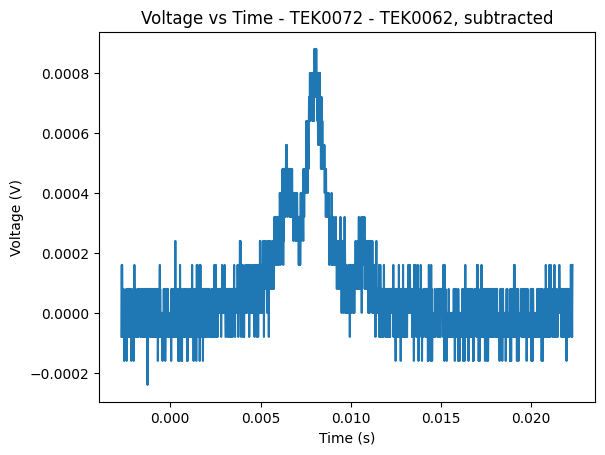

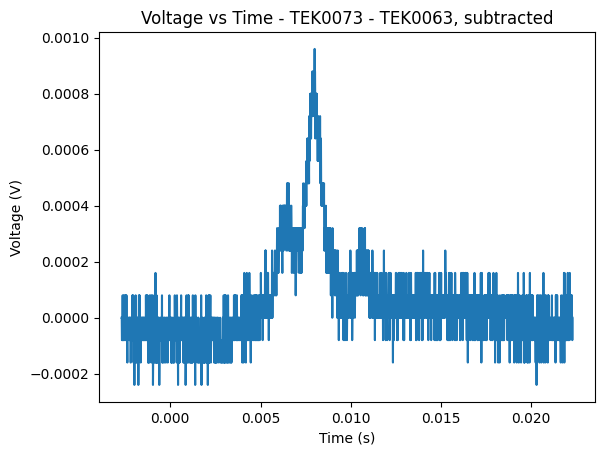

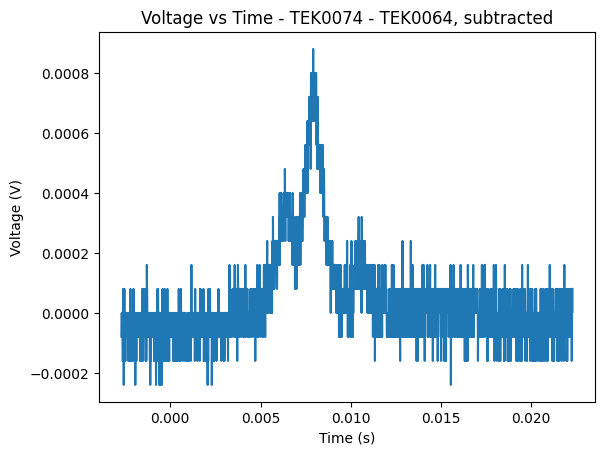

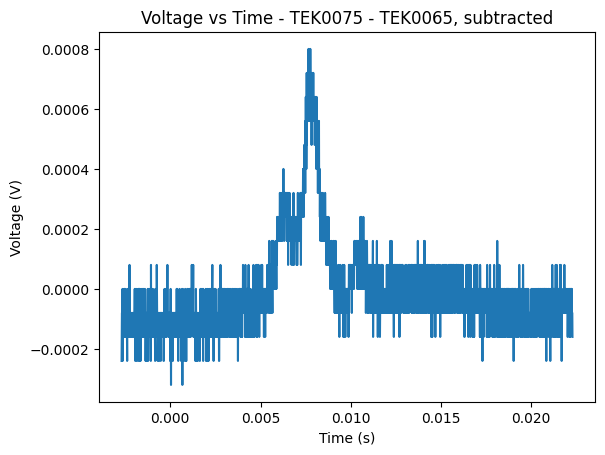

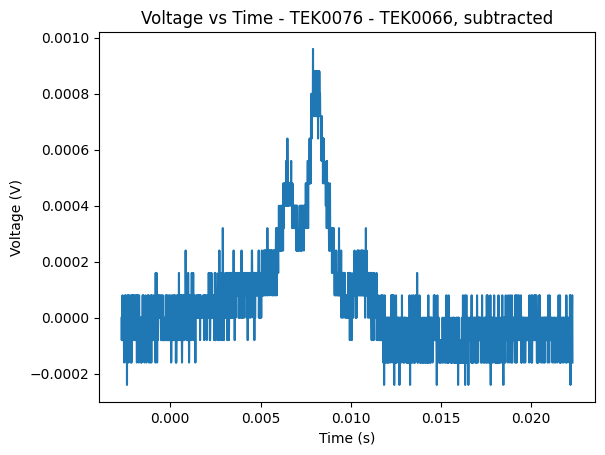

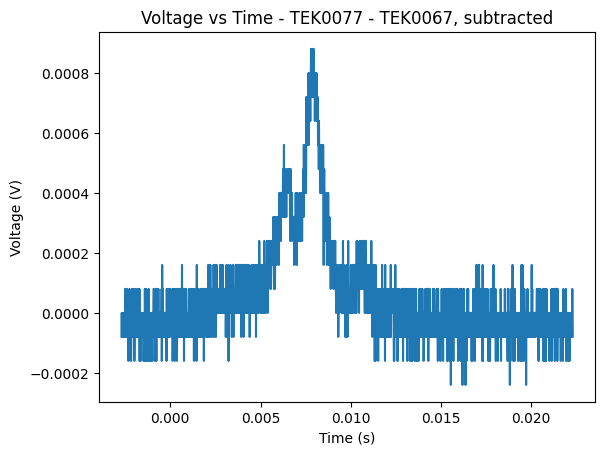

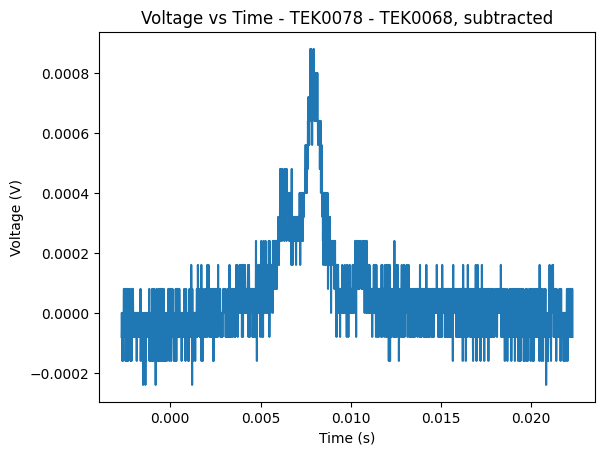

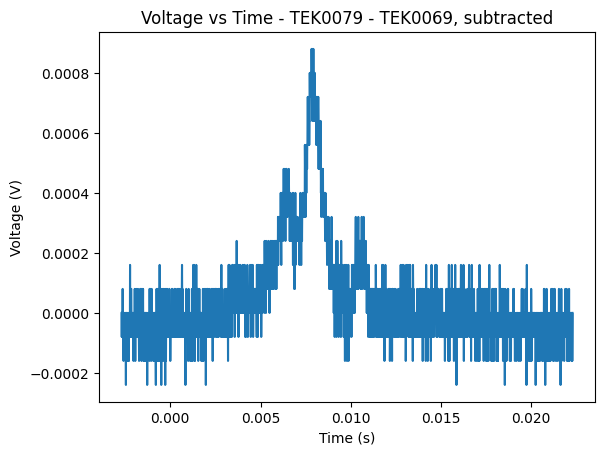

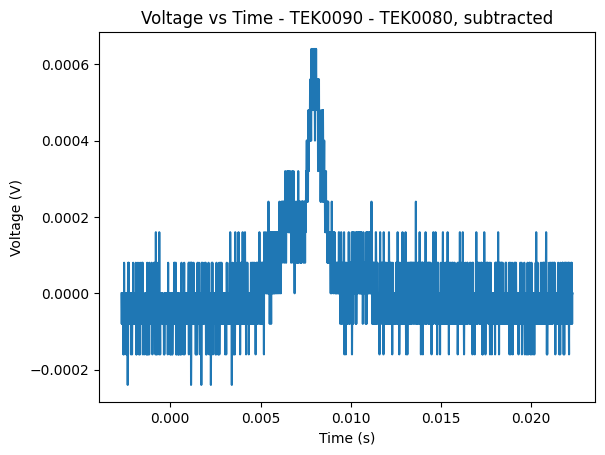

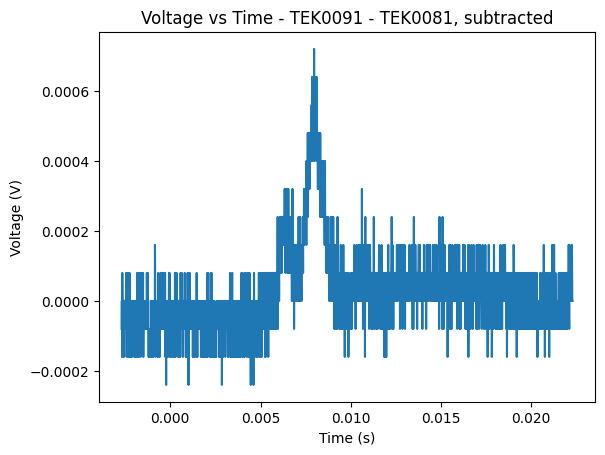

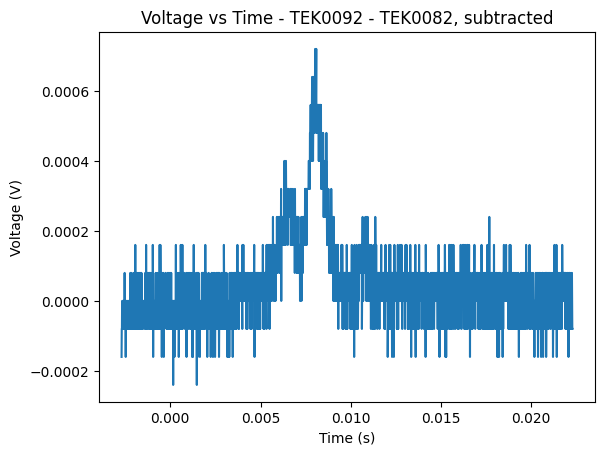

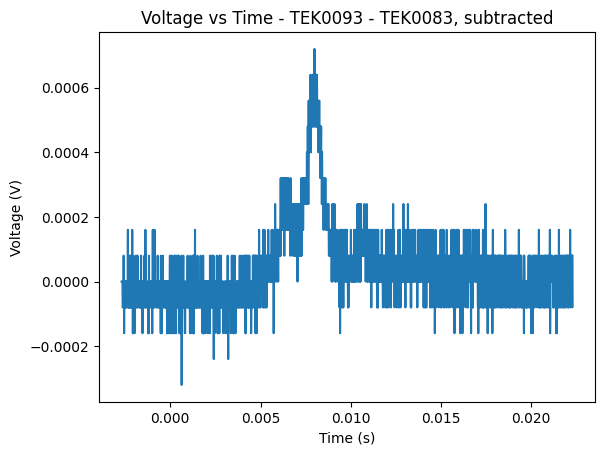

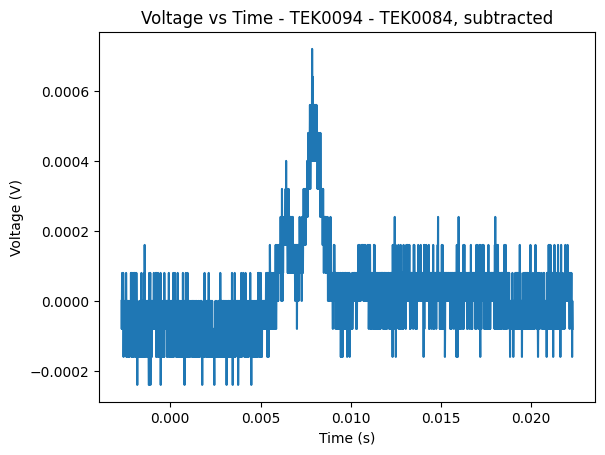

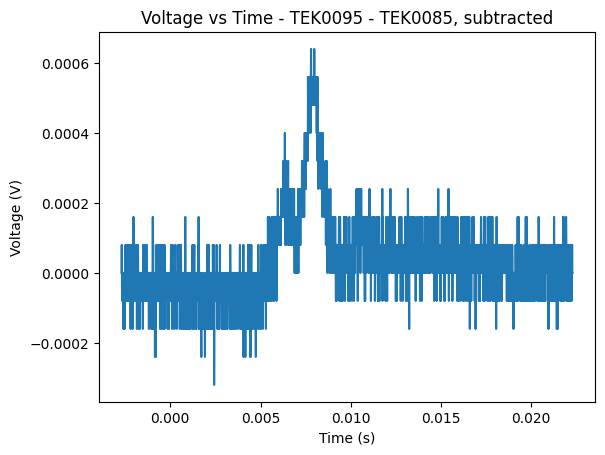

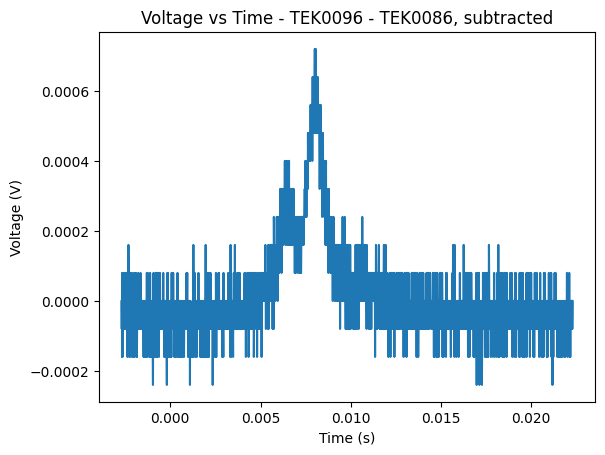

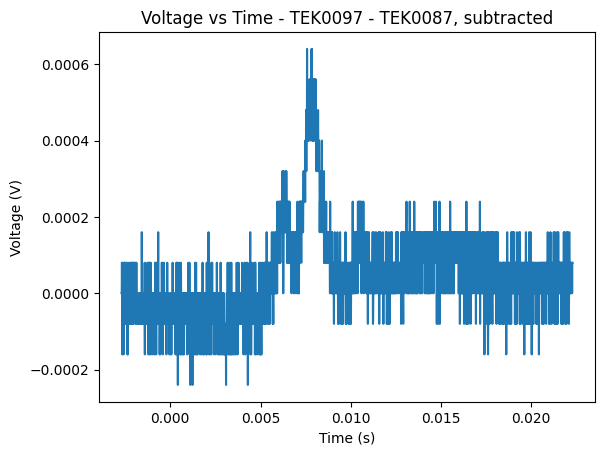

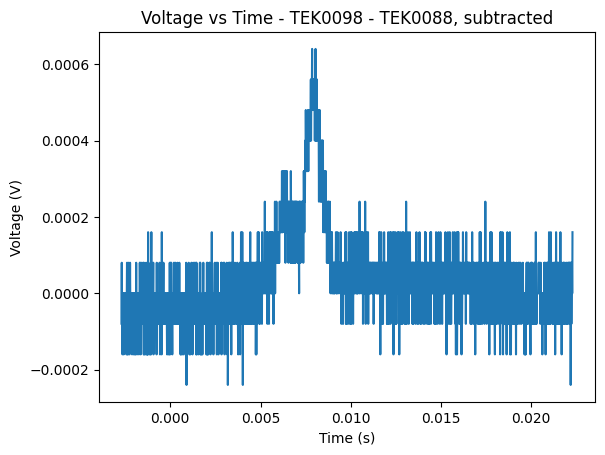

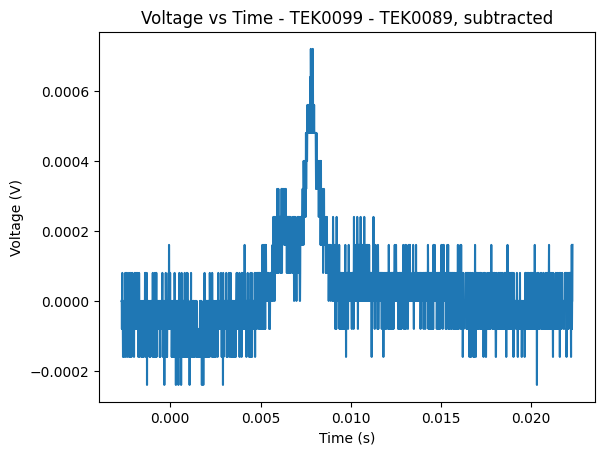

In [38]:
data_folder = r"/Users/timwiemer/Desktop/Natuur  en Sterrenkunde/Jaar 1/Rubium_Spectroscopy_group_11/Cross_over_dips_2026_06_11_16_avg"
xjes, ytjes = file_data(data_folder,100)

In [42]:
x_jes_1 = []
y_jes_1 = []

x_jes_2 = []
y_jes_2 = []

x_jes_3 = []
y_jes_3 = []

x_jes_4 = []
y_jes_4 = []

x_jes_5 = []
y_jes_5 = []

for i in range (0,10):
    x_jes_1.append(xjes[i])
    y_jes_1.append(ytjes[i])

for i in range (10,20):
    x_jes_2.append(xjes[i])
    y_jes_2.append(ytjes[i])

for i in range (20,30):
    x_jes_3.append(xjes[i])
    y_jes_3.append(ytjes[i])

for i in range (30,40):
    x_jes_4.append(xjes[i])
    y_jes_4.append(ytjes[i])

for i in range (40,50):
    x_jes_5.append(xjes[i])
    y_jes_5.append(ytjes[i])



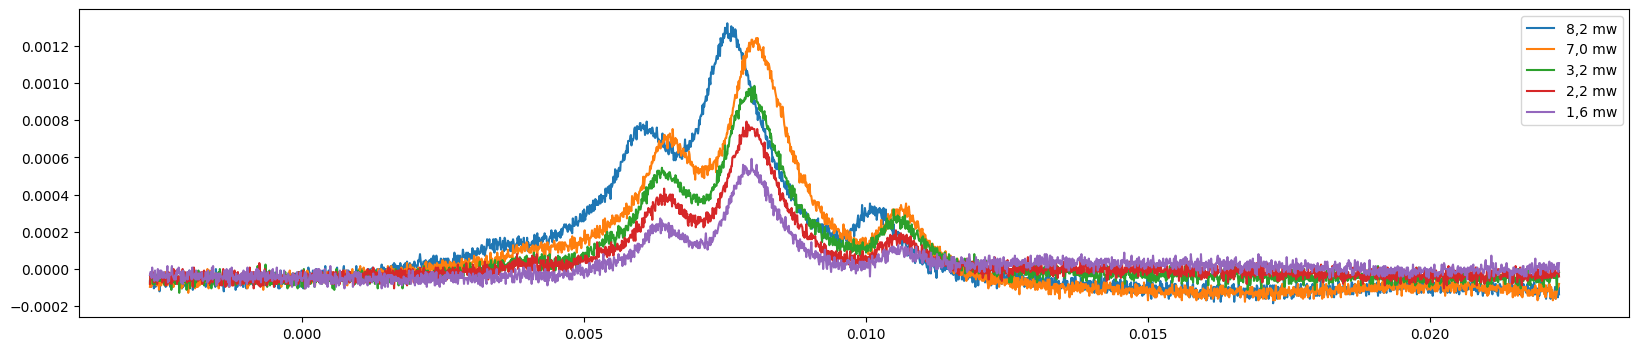

In [97]:
x_avg_1, y_avg_1 = gemiddelde_grafiek(x_jes_1,y_jes_1)
x_avg_2, y_avg_2 = gemiddelde_grafiek(x_jes_2,y_jes_2)
x_avg_3, y_avg_3 = gemiddelde_grafiek(x_jes_3,y_jes_3)
x_avg_4, y_avg_4 = gemiddelde_grafiek(x_jes_4,y_jes_4)
x_avg_5, y_avg_5 = gemiddelde_grafiek(x_jes_5,y_jes_5)

plt.figure(figsize=(20,4))
plt.plot(x_avg_1,y_avg_1, label ="8,2 mw")
plt.plot(x_avg_2,y_avg_2, label ="7,0 mw")
plt.plot(x_avg_3,y_avg_3, label ="3,2 mw")
plt.plot(x_avg_4,y_avg_4, label ="2,2 mw")
plt.plot(x_avg_5,y_avg_5, label ="1,6 mw")
plt.legend()
plt.show()

─────────────────────────────────────────────
Piek 1:
  x0    = 0.00599 ± 0.00000
  gamma = 0.00051 ± 0.00001
  A     = 0.00053 ± 0.00001
Piek 2:
  x0    = 0.00763 ± 0.00000
  gamma = 0.00068 ± 0.00001
  A     = 0.00121 ± 0.00001
Piek 3:
  x0    = 0.01021 ± 0.00001
  gamma = -0.00048 ± 0.00001
  A     = 0.00029 ± 0.00000
Piek 4:
  x0    = 0.00477 ± 0.00012
  gamma = -0.00318 ± 0.00010
  A     = 0.00021 ± 0.00001
Achtergrond B = -0.00012 ± 0.00000
─────────────────────────────────────────────


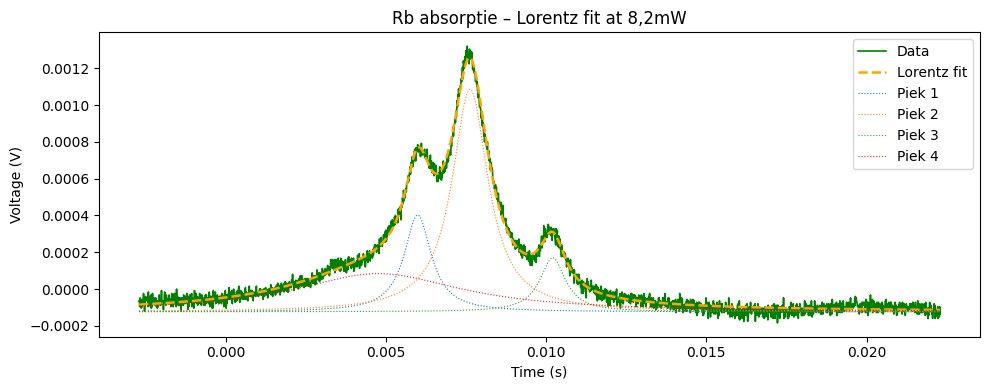

─────────────────────────────────────────────
Piek 1:
  x0    = 0.00644 ± 0.00000
  gamma = 0.00050 ± 0.00001
  A     = 0.00053 ± 0.00001
Piek 2:
  x0    = 0.00809 ± 0.00000
  gamma = 0.00064 ± 0.00001
  A     = 0.00119 ± 0.00001
Piek 3:
  x0    = 0.01067 ± 0.00001
  gamma = 0.00043 ± 0.00001
  A     = 0.00033 ± 0.00000
Piek 4:
  x0    = 0.00475 ± 0.00012
  gamma = 0.00337 ± 0.00013
  A     = 0.00018 ± 0.00000
Achtergrond B = -0.00013 ± 0.00000
─────────────────────────────────────────────


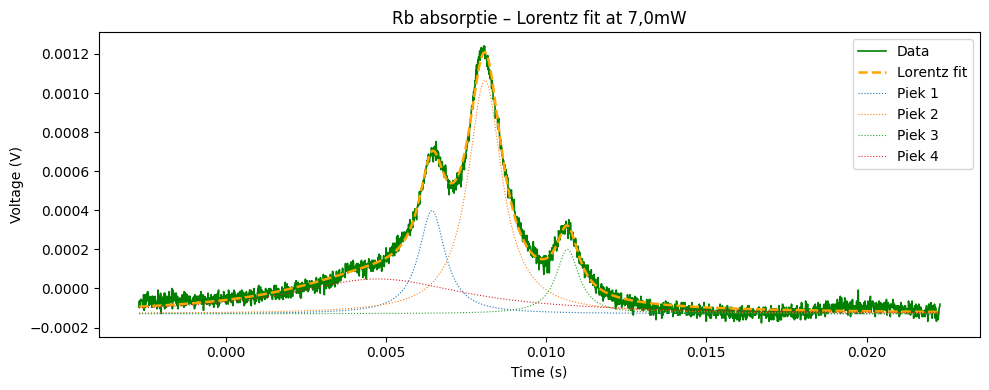

─────────────────────────────────────────────
Piek 1:
  x0    = 0.00636 ± 0.00001
  gamma = 0.00046 ± 0.00001
  A     = 0.00042 ± 0.00001
Piek 2:
  x0    = 0.00799 ± 0.00000
  gamma = 0.00061 ± 0.00000
  A     = 0.00095 ± 0.00000
Piek 3:
  x0    = 0.01062 ± 0.00001
  gamma = -0.00050 ± 0.00001
  A     = 0.00025 ± 0.00000
Piek 4:
  x0    = 0.00519 ± 0.00019
  gamma = -0.00136 ± 0.00017
  A     = 0.00006 ± 0.00001
Achtergrond B = -0.00005 ± 0.00000
─────────────────────────────────────────────


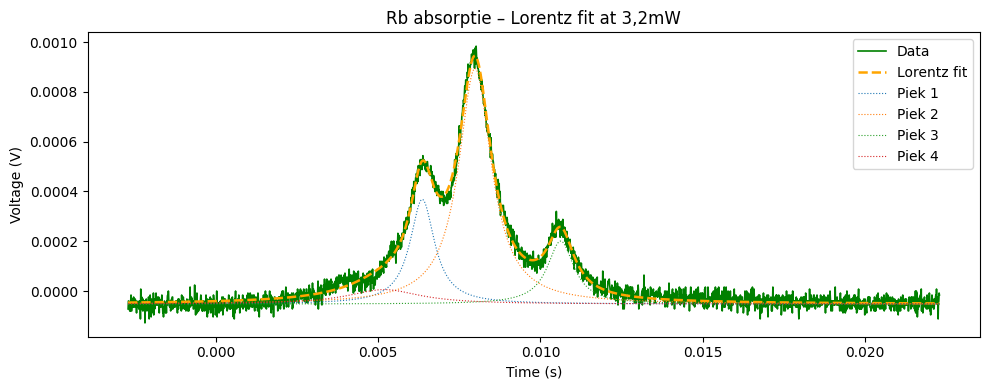

─────────────────────────────────────────────
Piek 1:
  x0    = 0.00636 ± 0.00001
  gamma = -0.00051 ± 0.00001
  A     = 0.00033 ± 0.00000
Piek 2:
  x0    = 0.00799 ± 0.00000
  gamma = 0.00054 ± 0.00001
  A     = 0.00075 ± 0.00000
Piek 3:
  x0    = 0.01064 ± 0.00001
  gamma = 0.00038 ± 0.00002
  A     = 0.00016 ± 0.00000
Piek 4:
  x0    = -0.00061 ± 0.00012
  gamma = 0.00202 ± 0.00023
  A     = -0.00004 ± 0.00000
Achtergrond B = -0.00002 ± 0.00000
─────────────────────────────────────────────


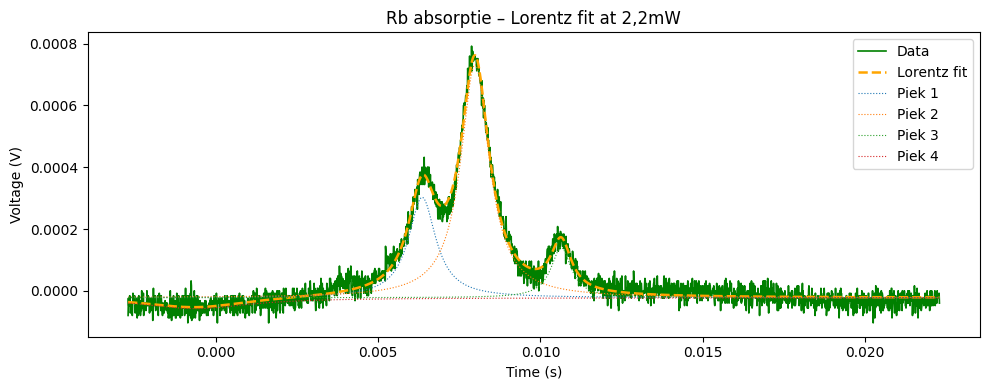

─────────────────────────────────────────────
Piek 1:
  x0    = 0.00634 ± 0.00001
  gamma = -0.00039 ± 0.00001
  A     = 0.00023 ± 0.00000
Piek 2:
  x0    = 0.00797 ± 0.00000
  gamma = 0.00049 ± 0.00001
  A     = 0.00056 ± 0.00000
Piek 3:
  x0    = 0.01064 ± 0.00002
  gamma = 0.00031 ± 0.00003
  A     = 0.00009 ± 0.00000
Piek 4:
  x0    = 0.01505 ± 0.00011
  gamma = -0.00567 ± 0.00028
  A     = 0.00009 ± 0.00000
Achtergrond B = -0.00006 ± 0.00000
─────────────────────────────────────────────


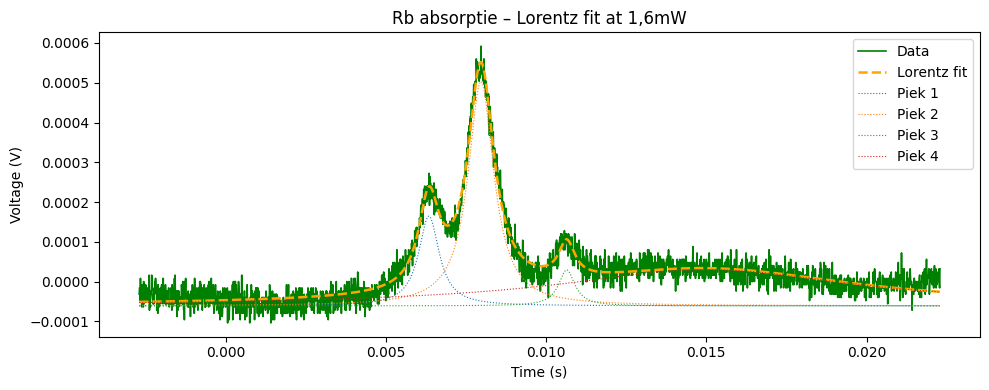

In [106]:
x0_1_list  = [0.006, 0.008, 0.010, 0.004]
A_1_list   = [0.00083, 0.0012, 0.0004, 0.0002]

popt_1, perr_1 = lorentz_fit(
    x_avg_1, y_avg_1,
    x0_list     = x0_1_list,
    A_list      = A_1_list,
    gamma_guess = 0.0001,
    B_guess     = 0.001,
    title       = 'Rb absorptie – Lorentz fit at 8,2mW'
)

x0_2_list  = [0.006, 0.008, 0.010, 0.004]
A_2_list   = [0.00083, 0.0012, 0.0004, 0.0002]

popt_2, perr_2 = lorentz_fit(
    x_avg_2, y_avg_2,
    x0_list     = x0_2_list,
    A_list      = A_2_list,
    gamma_guess = 0.0001,
    B_guess     = 0.001,
    title       = 'Rb absorptie – Lorentz fit at 7,0mW'
)

x0_3_list  = [0.006, 0.008, 0.010, 0.004]
A_3_list   = [0.00083, 0.0012, 0.0004, 0.0002]

popt_3, perr_3 = lorentz_fit(
    x_avg_3, y_avg_3,
    x0_list     = x0_3_list,
    A_list      = A_3_list,
    gamma_guess = 0.0001,
    B_guess     = 0.001,
    title       = 'Rb absorptie – Lorentz fit at 3,2mW'
) 

x0_4_list  = [0.007, 0.008, 0.011, 0.003]
A_4_list   = [0.00083, 0.0012, 0.0004, 0.0002]

popt_4, perr_4 = lorentz_fit(
    x_avg_4, y_avg_4,
    x0_list     = x0_4_list,
    A_list      = A_4_list,
    gamma_guess = 0.0001,
    B_guess     = 0.001,
    title       = 'Rb absorptie – Lorentz fit at 2,2mW'
)

x0_5_list  = [0.007, 0.008, 0.011, 0.015]
A_5_list   = [0.00083, 0.0012, 0.0002, 0.001]

popt_5, perr_5 = lorentz_fit(
    x_avg_5, y_avg_5,
    x0_list     = x0_5_list,
    A_list      = A_5_list,
    gamma_guess = 0.0001,
    B_guess     = 0.001,
    title       = 'Rb absorptie – Lorentz fit at 1,6mW'
)

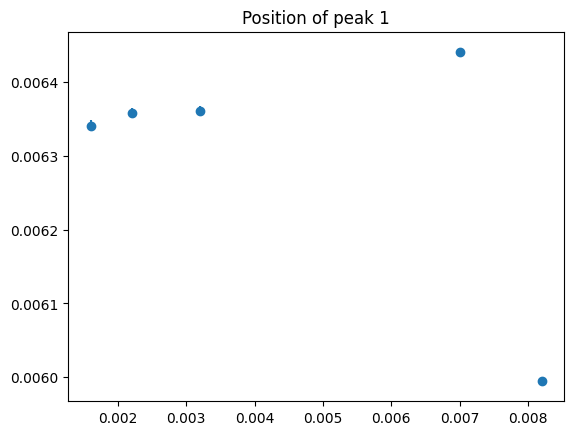

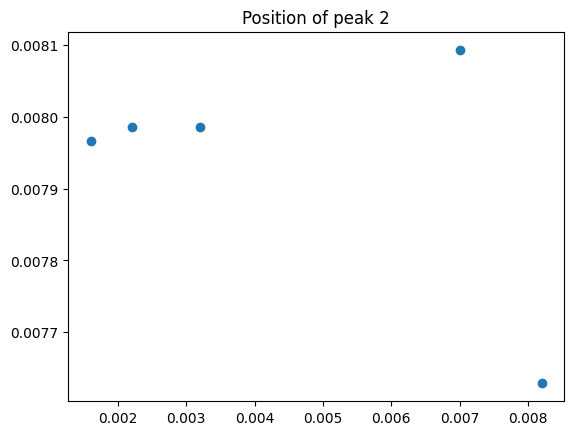

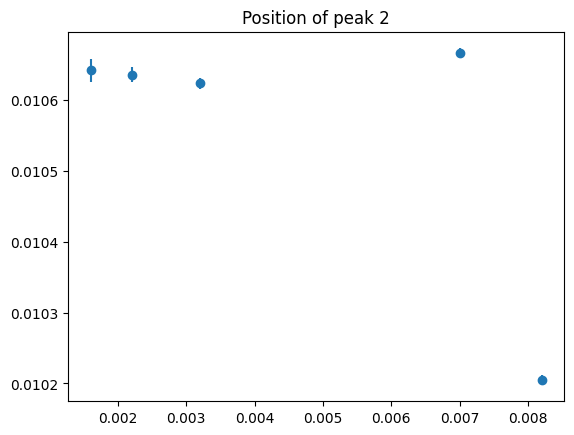

In [ ]:
Power = [8.2E-3, 7.0E-3, 3.2E-3, 2.2E-3, 1.6E-3]
x_0_piek_1 = [popt_1[0],popt_2[0], popt_3[0], popt_4[0], popt_5[0]]
x_0_piek_1_error = [perr_1[0],perr_2[0], perr_3[0], perr_4[0], perr_5[0]]
plt.errorbar(Power,x_0_piek_1,yerr = x_0_piek_1_error,  fmt = "o")
plt.title("Position of peak 1")
plt.show()



x_0_piek_2 = [popt_1[3],popt_2[3], popt_3[3], popt_4[3], popt_5[3]]
x_0_piek_2_error = [perr_1[3],perr_2[3], perr_3[3], perr_4[3], perr_5[3]]
plt.errorbar(Power,x_0_piek_2,yerr = x_0_piek_2_error, fmt = "o")
plt.title("Position of peak 2")
plt.show()

x_0_piek_3 = [popt_1[6],popt_2[6], popt_3[6], popt_4[6], popt_5[6]]
x_0_piek_3_error = [perr_1[6],perr_2[6], perr_3[6], perr_4[6], perr_5[6]]
plt.errorbar(Power,x_0_piek_3,yerr = x_0_piek_3_error, fmt = "o")
plt.title("Position of peak 2")
plt.show()
